In [1]:
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
import kagglehub
import copy
from sklearn.metrics import classification_report, confusion_matrix
from torch import nn,optim
from torch.nn.modules import pooling
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms, models

SEED = 42
BATCH_SIZE = 128
FAST_MODE = False
EPOCHS = 2 if FAST_MODE else 15
LEARNING_RATE = 0.05

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
    print(f'PyTorch: {torch.__version__}')

print("Using device:", device)

Using device: cuda


Download Dataset

In [2]:
pip install kagglehub

In [3]:
path = Path(kagglehub.dataset_download("mostafaabla/garbage-classification"))
print("Downloaded to:", path)
print("Top-level contents:", [p.name for p in path.iterdir()])

# Try common folder names used by this dataset.
candidates = [
    path / "garbage_classification",
    path / "Garbage classification",
    path
]

def looks_like_imagefolder(folder):
    if not folder.is_dir():
        return False
    class_dirs = [p for p in folder.iterdir() if p.is_dir()]
    # A valid root should have multiple class folders containing image files.
    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    folders_with_images = 0
    for class_dir in class_dirs:
        if any(f.is_file() and f.suffix.lower() in image_exts for f in class_dir.iterdir()):
            folders_with_images += 1
    return folders_with_images >= 2

DATA_DIR = next((p for p in candidates if looks_like_imagefolder(p)), None)

if DATA_DIR is None:
    # Search one level below the downloaded directory if its structure differs.
    possible = [p for p in path.iterdir() if p.is_dir()]
    DATA_DIR = next((p for p in possible if looks_like_imagefolder(p)), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate the class folders. Inspect the downloaded directory and set DATA_DIR manually."
    )

print("ImageFolder root:", DATA_DIR)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Downloaded to: /kaggle/input/garbage-classification
Top-level contents: ['garbage_classification']
ImageFolder root: /kaggle/input/garbage-classification/garbage_classification


Train/Validation/Test Split & Normalization

In [4]:
WASTE_MEAN = (0.485, 0.456, 0.406)
WASTE_STD = (0.229, 0.224, 0.225)

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=WASTE_MEAN, std=WASTE_STD)
])

DATA_DIR = Path(path) / 'garbage_classification'
if not DATA_DIR.exists():
    DATA_DIR = Path(path)

# 1. تحميل الداتا الكاملة باستخدام ImageFolder
full_dataset = datasets.ImageFolder(
    root=DATA_DIR,
    transform=transform
)

class_names = full_dataset.classes  # أسماء أنواع القمامة (مثل: plastic, paper, glass...)

# 2. تقسيم الداتا الكلية إلى Train و Validation و Test تلقائياً
split_generator = torch.Generator().manual_seed(SEED)

total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_full, val_full, test_full = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=split_generator
)

# 3. وضع الـ FAST_MODE للتجربة السريعة (اختياري عشان الكود يخلص بسرعة لو اختبرت)
if FAST_MODE:
    train_data = Subset(train_full, range(min(1_000, len(train_full))))
    val_data = Subset(val_full, range(min(200, len(val_full))))
    test_data = Subset(test_full, range(min(500, len(test_full))))
else:
    train_data, val_data, test_data = train_full, val_full, test_full

print('Classes:', class_names)
print(f'Split sizes — train: {len(train_data):,}, validation: {len(val_data):,}, test: {len(test_data):,}')

# 4. إنشاء الـ DataLoaders
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Split sizes — train: 10,860, validation: 2,327, test: 2,328


Image Preprocessing

In [5]:
IMG_SIZE = 128

# Image processing for training images
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])

# Image processing for validation and test images
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

DataLoaders

In [6]:
NUM_WORKERS = 0

# Reproducible shuffling for training
loader_generator = torch.Generator().manual_seed(SEED)

# Training DataLoader
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    generator=loader_generator
)

# Validation DataLoader
val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# Testing DataLoader
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# Inspect one training batch
images, labels = next(iter(train_loader))

print("Image batch shape:", tuple(images.shape))
print("Image data type:", images.dtype)

print("Label batch shape:", tuple(labels.shape))
print("Label data type:", labels.dtype)

print("Pixel range:", images.min().item(), "to", images.max().item())
print("First 10 labels:", labels[:10].tolist())

# Use the 'class_names' variable defined in the earlier cell instead of train_data.classes
print("Number of classes:", len(class_names))
print("Class names:", class_names)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Image batch shape: (128, 3, 128, 128)
Image data type: torch.float32
Label batch shape: (128,)
Label data type: torch.int64
Pixel range: -2.1179039478302 to 2.640000104904175
First 10 labels: [4, 9, 1, 4, 4, 4, 4, 7, 6, 4]
Number of classes: 12
Class names: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Training batches: 85
Validation batches: 19
Testing batches: 19


CNN Architecture

In [7]:
class CNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(
                in_channels=32,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(in_channels=32,
                      out_channels=64,
                      kernel_size=3,
                      padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
                ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 4
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),


            nn.AdaptiveAvgPool2d((4, 4)),
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


num_classes = len(class_names)   # تم استخدام متغير class_names بدلاً من train_data.classes
model = CNN(num_classes)

loss + optimizer

In [8]:
# Pass the required 'num_classes' parameter to CNN
model = CNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001
)

print(model)
print("Device:", device)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
 

Training and Validation

In [9]:
train_loss_history = []
train_accuracy_history = []
val_loss_history = []
val_accuracy_history = []

best_val_accuracy = -1.0
best_epoch = 0
best_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    # -------- Training --------
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_count += images.size(0)

    train_loss = train_loss_sum / train_count
    train_accuracy = 100.0 * train_correct / train_count
    train_loss_history.append(train_loss)
    train_accuracy_history.append(train_accuracy)

    # -------- Validation --------
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_count += labels.size(0)

    val_loss = val_loss_sum / val_count
    val_accuracy = 100.0 * val_correct / val_count

    val_loss_history.append(val_loss)
    val_accuracy_history.append(val_accuracy)

    # Keep the model that performs best on validation data.
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict": best_weights,
            "class_names": class_names,
            "img_size": IMG_SIZE,
            "mean": WASTE_MEAN,
            "std": WASTE_STD,
        }, "best_waste_cnn.pth")

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

# Restore the best validation checkpoint before final testing.
model.load_state_dict(best_weights)
print(f"Best validation accuracy: {best_val_accuracy:.2f}% at epoch {best_epoch}")

Epoch [1/15] | Train Loss: 1.6173 | Train Acc: 48.50% | Val Loss: 1.1927 | Val Accuracy: 59.52%
Epoch [2/15] | Train Loss: 1.1728 | Train Acc: 60.89% | Val Loss: 1.0814 | Val Accuracy: 62.78%
Epoch [3/15] | Train Loss: 1.0408 | Train Acc: 65.75% | Val Loss: 0.9704 | Val Accuracy: 67.08%
Epoch [4/15] | Train Loss: 0.9345 | Train Acc: 69.13% | Val Loss: 0.8271 | Val Accuracy: 72.32%
Epoch [5/15] | Train Loss: 0.8853 | Train Acc: 71.34% | Val Loss: 0.8087 | Val Accuracy: 73.66%
Epoch [6/15] | Train Loss: 0.8135 | Train Acc: 73.90% | Val Loss: 0.7792 | Val Accuracy: 74.43%
Epoch [7/15] | Train Loss: 0.7671 | Train Acc: 75.45% | Val Loss: 0.7912 | Val Accuracy: 74.34%
Epoch [8/15] | Train Loss: 0.7239 | Train Acc: 76.36% | Val Loss: 0.7644 | Val Accuracy: 75.33%
Epoch [9/15] | Train Loss: 0.6754 | Train Acc: 78.04% | Val Loss: 0.8151 | Val Accuracy: 73.79%
Epoch [10/15] | Train Loss: 0.6487 | Train Acc: 78.69% | Val Loss: 0.6754 | Val Accuracy: 78.81%
Epoch [11/15] | Train Loss: 0.6168 | Tr

Plot curves

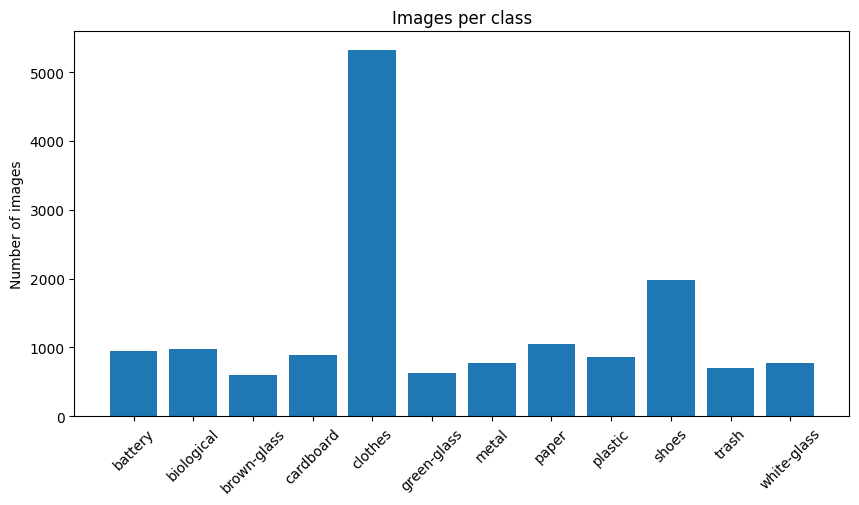

Largest class share: 34.3 %


In [11]:
# Use full_dataset.targets to count the occurrences of each class
counts = np.bincount(full_dataset.targets, minlength=num_classes)

plt.figure(figsize=(10, 5))
plt.bar(class_names, counts)
plt.xticks(rotation=45)
plt.title("Images per class")
plt.ylabel("Number of images")
plt.show()

print("Largest class share:", round(100 * counts.max() / counts.sum(), 1), "%")

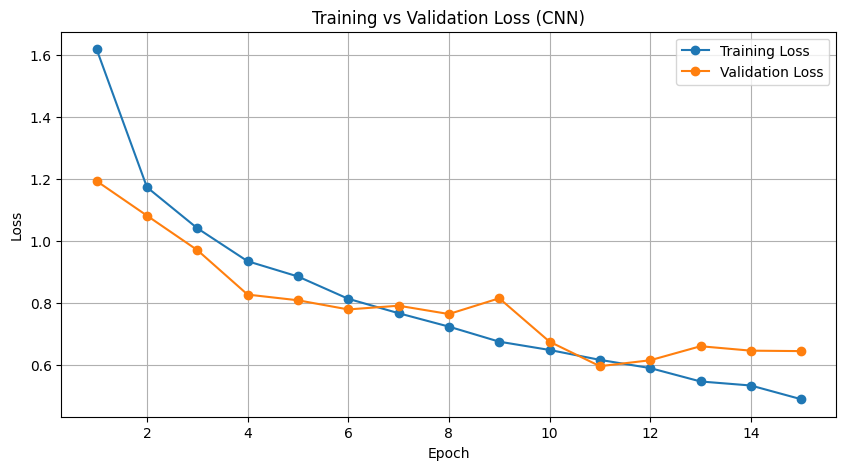

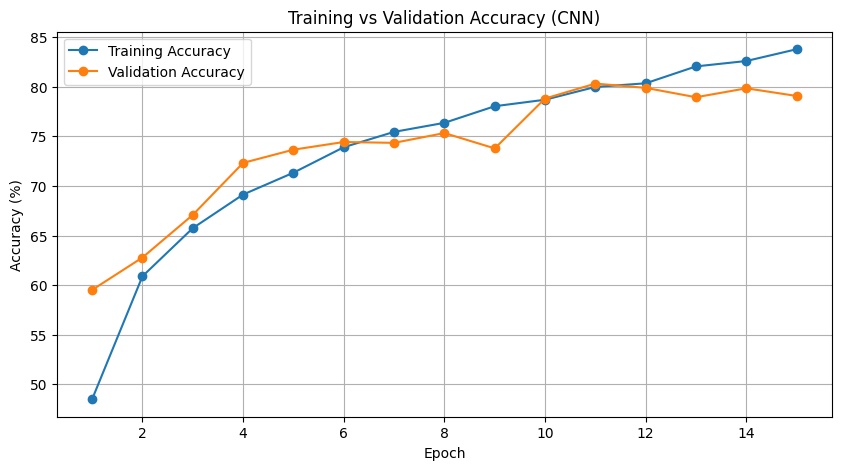

In [12]:
epochs_range = range(1, len(train_loss_history) + 1)

# Training Loss vs Validation Loss
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_loss_history, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss_history, marker="o", label="Validation Loss")

plt.title("Training vs Validation Loss (CNN)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Training Accuracy vs Validation Accuracy
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_accuracy_history, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_accuracy_history, marker="o", label="Validation Accuracy")

plt.title("Training vs Validation Accuracy (CNN)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

Final Test Evaluation

In [17]:
model.eval()
test_loss_sum = 0.0
test_correct = 0
test_count = 0
class_correct = [0] * num_classes
class_total = [0] * num_classes

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)
        predictions = outputs.argmax(dim=1)

        test_loss_sum += loss.item() * images.size(0)
        test_correct += (predictions == labels).sum().item()
        test_count += labels.size(0)

        for label, prediction in zip(labels, predictions):
            label_id = label.item()
            class_total[label_id] += 1
            if label == prediction:
                class_correct[label_id] += 1

test_loss = test_loss_sum / test_count
test_accuracy = 100.0 * test_correct / test_count

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {test_correct}/{test_count}")

print("\nAccuracy by class:")
for i, name in enumerate(class_names):
    if class_total[i] > 0:
        class_acc = 100.0 * class_correct[i] / class_total[i]
        print(f"{name}: {class_acc:.2f}% ({class_correct[i]}/{class_total[i]})")
    else:
        print(f"{name}: no test examples")

Test Loss: 0.5938
Test Accuracy: 81.40%
Correct predictions: 1895/2328

Accuracy by class:
battery: 62.65% (104/166)
biological: 74.40% (93/125)
brown-glass: 77.89% (74/95)
cardboard: 79.34% (96/121)
clothes: 95.97% (762/794)
green-glass: 89.08% (106/119)
metal: 51.82% (57/110)
paper: 80.62% (129/160)
plastic: 63.33% (76/120)
shoes: 82.62% (252/305)
trash: 75.23% (82/109)
white-glass: 61.54% (64/104)


Confusion Matrix

              precision    recall  f1-score   support

     battery      0.897     0.627     0.738       166
  biological      0.788     0.744     0.765       125
 brown-glass      0.831     0.779     0.804        95
   cardboard      0.800     0.793     0.797       121
     clothes      0.927     0.960     0.943       794
 green-glass      0.855     0.891     0.872       119
       metal      0.648     0.518     0.576       110
       paper      0.806     0.806     0.806       160
     plastic      0.524     0.633     0.574       120
       shoes      0.764     0.826     0.794       305
       trash      0.796     0.752     0.774       109
 white-glass      0.566     0.615     0.590       104

    accuracy                          0.814      2328
   macro avg      0.767     0.745     0.753      2328
weighted avg      0.817     0.814     0.813      2328



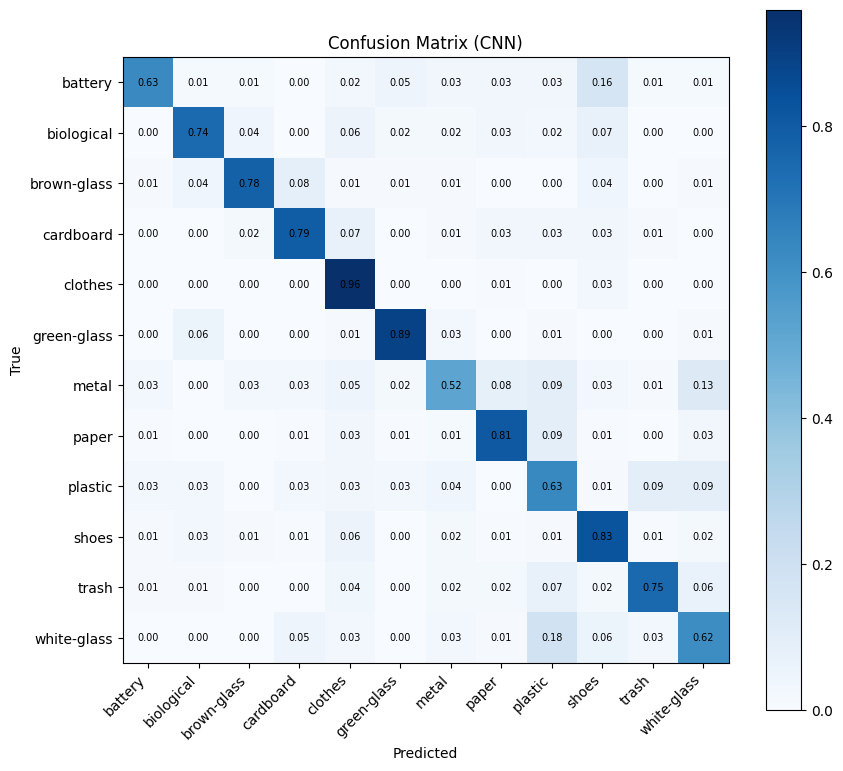

In [19]:
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1)

        # Collect predictions and true labels
        all_preds.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

# Print classification report
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

# Plot the normalized Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
cm = cm / cm.sum(axis=1, keepdims=True)   # Normalize row-wise

plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(num_classes), class_names, rotation=45, ha="right")
plt.yticks(range(num_classes), class_names)

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (CNN)")
plt.tight_layout()
plt.show()

Transfer Learning (resnet)

In [20]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, num_classes)
resnet = resnet.to(device)

resnet_optimizer = optim.Adam(resnet.parameters(), LEARNING_RATE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 104MB/s]


In [21]:
EPOCHS_TL = 15

resnet_train_loss_history = []
resnet_val_loss_history = []
resnet_val_accuracy_history = []

best_resnet_val = -1.0
best_resnet_weights = copy.deepcopy(resnet.state_dict())

for epoch in range(EPOCHS_TL):
    # -------- Training --------
    resnet.train()
    train_loss_sum = 0.0
    train_count = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()
        outputs = resnet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        resnet_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_count += images.size(0)

    train_loss = train_loss_sum / train_count
    resnet_train_loss_history.append(train_loss)

    # -------- Validation --------
    resnet.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_count += labels.size(0)

    val_loss = val_loss_sum / val_count
    val_accuracy = 100.0 * val_correct / val_count

    resnet_val_loss_history.append(val_loss)
    resnet_val_accuracy_history.append(val_accuracy)

    if val_accuracy > best_resnet_val:
        best_resnet_val = val_accuracy
        best_resnet_weights = copy.deepcopy(resnet.state_dict())
        torch.save(best_resnet_weights, "best_resnet18.pth")

    print(
        f"Epoch [{epoch + 1}/{EPOCHS_TL}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

resnet.load_state_dict(best_resnet_weights)
print(f"Best ResNet18 validation accuracy: {best_resnet_val:.2f}%")

Epoch [1/15] | Train Loss: 2.6651 | Val Loss: 3.3282 | Val Accuracy: 39.45%
Epoch [2/15] | Train Loss: 1.6906 | Val Loss: 1.5787 | Val Accuracy: 45.94%
Epoch [3/15] | Train Loss: 1.4190 | Val Loss: 1.4329 | Val Accuracy: 53.46%
Epoch [4/15] | Train Loss: 1.2622 | Val Loss: 1.1822 | Val Accuracy: 59.65%
Epoch [5/15] | Train Loss: 1.1750 | Val Loss: 1.1584 | Val Accuracy: 62.61%
Epoch [6/15] | Train Loss: 1.0767 | Val Loss: 1.1874 | Val Accuracy: 60.16%
Epoch [7/15] | Train Loss: 1.0083 | Val Loss: 0.9697 | Val Accuracy: 67.25%
Epoch [8/15] | Train Loss: 0.9470 | Val Loss: 1.2980 | Val Accuracy: 62.44%
Epoch [9/15] | Train Loss: 0.8950 | Val Loss: 0.9938 | Val Accuracy: 68.72%
Epoch [10/15] | Train Loss: 0.8462 | Val Loss: 1.1888 | Val Accuracy: 61.24%
Epoch [11/15] | Train Loss: 0.8147 | Val Loss: 1.1277 | Val Accuracy: 61.07%
Epoch [12/15] | Train Loss: 0.7637 | Val Loss: 1.0588 | Val Accuracy: 65.49%
Epoch [13/15] | Train Loss: 0.7241 | Val Loss: 1.1406 | Val Accuracy: 65.15%
Epoch [1

In [23]:
resnet.eval()
resnet_preds = []
resnet_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = resnet(images.to(device))
        resnet_preds.extend(outputs.argmax(dim=1).cpu().tolist())
        resnet_labels.extend(labels.tolist())

resnet_test_accuracy = 100.0 * np.mean(np.array(resnet_preds) == np.array(resnet_labels))

print(f"ResNet18 Test Accuracy: {resnet_test_accuracy:.2f}%")
print(classification_report(resnet_labels, resnet_preds, target_names=class_names, digits=3))

ResNet18 Test Accuracy: 69.20%
              precision    recall  f1-score   support

     battery      0.796     0.494     0.610       166
  biological      0.771     0.512     0.615       125
 brown-glass      0.750     0.632     0.686        95
   cardboard      0.712     0.694     0.703       121
     clothes      0.771     0.975     0.861       794
 green-glass      0.782     0.933     0.851       119
       metal      0.449     0.282     0.346       110
       paper      0.529     0.738     0.616       160
     plastic      0.541     0.275     0.365       120
       shoes      0.631     0.577     0.603       305
       trash      0.705     0.284     0.405       109
 white-glass      0.385     0.452     0.416       104

    accuracy                          0.692      2328
   macro avg      0.652     0.571     0.590      2328
weighted avg      0.687     0.692     0.672      2328



Compare the Two Models

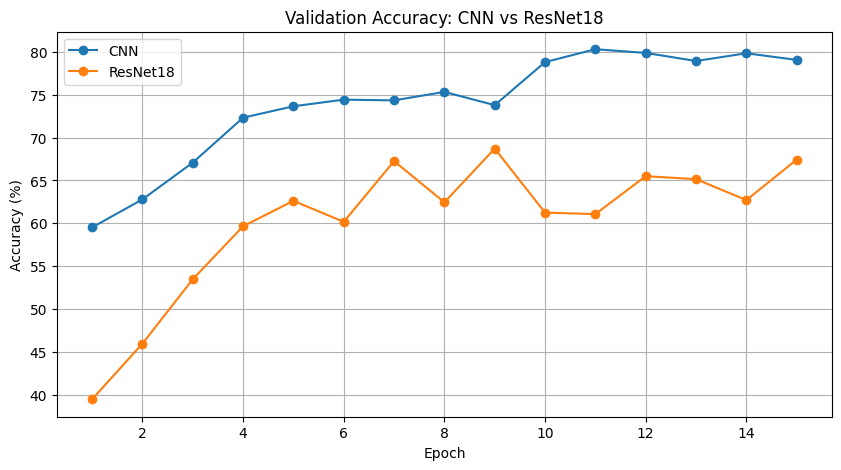

CNN Test Accuracy:      81.40%
ResNet18 Test Accuracy: 69.20%


In [24]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(val_accuracy_history) + 1), val_accuracy_history, marker="o", label="CNN")
plt.plot(range(1, len(resnet_val_accuracy_history) + 1), resnet_val_accuracy_history, marker="o", label="ResNet18")

plt.title("Validation Accuracy: CNN vs ResNet18")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()

print(f"CNN Test Accuracy:      {test_accuracy:.2f}%")
print(f"ResNet18 Test Accuracy: {resnet_test_accuracy:.2f}%")

Some missclassified data

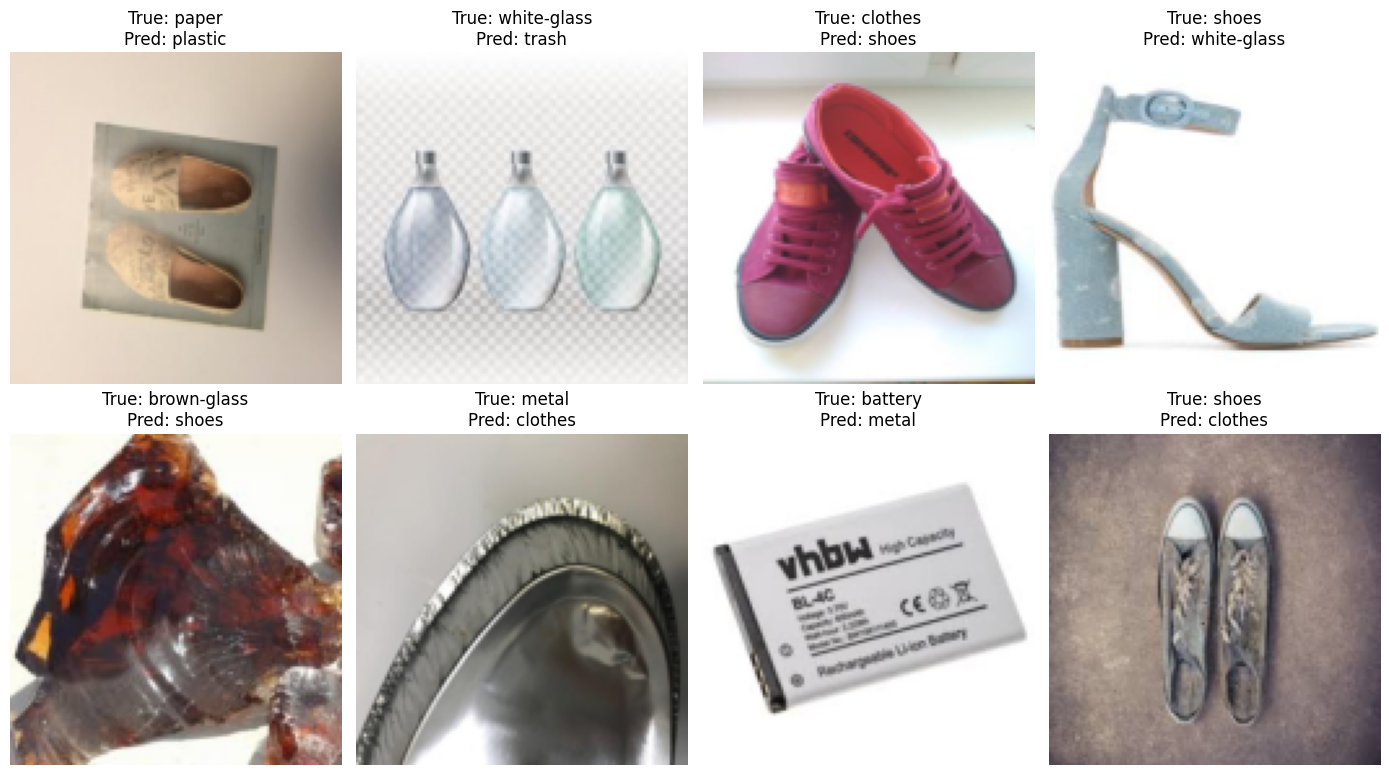

In [26]:
# Collect a few incorrect predictions to understand common errors.
wrong_images = []
wrong_true = []
wrong_pred = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        for image, label, prediction in zip(images, labels, predictions):
            if label.item() != prediction.item():
                wrong_images.append(image)
                wrong_true.append(class_names[label.item()])
                wrong_pred.append(class_names[prediction.item()])
            if len(wrong_images) >= 8:
                break
        if len(wrong_images) >= 8:
            break

if not wrong_images:
    print("No incorrect examples found in the batches checked.")
else:
    # Undo normalization only for display.
    mean = torch.tensor(WASTE_MEAN).view(3, 1, 1)
    std = torch.tensor(WASTE_STD).view(3, 1, 1)

    cols = 4
    rows = (len(wrong_images) + cols - 1) // cols
    plt.figure(figsize=(14, 4 * rows))

    for i, image in enumerate(wrong_images):
        image = image * std + mean
        image = image.clamp(0, 1).permute(1, 2, 0).numpy()

        plt.subplot(rows, cols, i + 1)
        plt.imshow(image)
        plt.title(f"True: {wrong_true[i]}\nPred: {wrong_pred[i]}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

Save and reload the model

In [27]:
checkpoint_path = "best_waste_cnn.pth"

# The checkpoint was saved when validation accuracy improved.
checkpoint = torch.load(checkpoint_path, map_location=device)
loaded_model = CNN(num_classes).to(device)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

print("Model checkpoint loaded successfully:", checkpoint_path)
print("Saved classes:", checkpoint["class_names"])

Model checkpoint loaded successfully: best_waste_cnn.pth
Saved classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


Predict One new image

In [28]:
IMAGE_PATH = "/content/my_waste_image.jpg"  # Change this to your image path

def predict_image(image_path, model, class_names):
    image = Image.open(image_path).convert("RGB")
    image_tensor = eval_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]
        predicted_index = probabilities.argmax().item()

    print("Predicted class:", class_names[predicted_index])
    print(f"Confidence: {probabilities[predicted_index].item() * 100:.2f}%")

    plt.imshow(image)
    plt.title(f"Prediction: {class_names[predicted_index]}")
    plt.axis("off")
    plt.show()